# Mood-Based Song Recommender: from a driver's face to a safer playlist

## 1. Introduction

**Goal.** Recommend songs from a facial expression, and adapt the recommendation to a driving context. Listening to music is one of the most common activities in a car, and music is linked to emotions. If a car can read the driver's expression, it can choose music that matches their taste while steering them towards a calmer, more attentive state.

**Two datasets, linked by emotion.**

| Dataset | Content | Role in the project |
|---|---|---|
| [Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) | 114,000 rows, one per track and genre, with audio features computed by Spotify (`valence`, `energy`, `tempo`, ...) | The music side: each song gets a position on an emotional map |
| [FER-2013](https://www.kaggle.com/datasets/msambare/fer2013) | 35,887 grayscale face images (48×48 pixels) labelled with 7 emotions | The face side: we trained an image classifier on it |

**How the two datasets are joined.** They share no common column. The bridge is a two-axis emotional map used in psychology (Russell's circumplex model): **valence** (negative ↔ positive) and **arousal** (calm ↔ excited). Spotify gives every song a `valence` and an `energy` score between 0 and 1. Our classifier gives every face 7 emotion probabilities, which we convert into a point on the same map.

**Pipeline.**

`face image → classifier → 7 probabilities → point (valence, energy) → nearest songs → filtered by taste and by driving rules`

**About the classifier.** Training a neural network needs a GPU and several minutes, so it is done in a separate notebook (`train_emotion_classifier.ipynb`, run on Google Colab). That notebook exports `predictions_test.csv`: one row per test image, with the true emotion, the predicted emotion and the 7 probabilities. This notebook loads that file, so it runs in a few seconds on any laptop.

## 2. Data Loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("data")

# Music side: the Spotify Tracks Dataset, exactly as downloaded from Kaggle
tracks_raw = pd.read_csv(DATA_DIR / "spotify_tracks.csv")
print("Spotify file - rows and columns:", tracks_raw.shape)
tracks_raw.head()

Spotify file - rows and columns: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Soundtrack),Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [2]:
# Face side: the output of our classifier on the 7,178 FER-2013 test images
faces = pd.read_csv(DATA_DIR / "predictions_test.csv")
print("Predictions file - rows and columns:", faces.shape)
faces.head()

Predictions file - rows and columns: (7178, 10)


,image,true_emotion,predicted_emotion,p_angry,p_disgust,p_fear,p_happy,p_neutral,p_sad,p_surprise
0,test/angry/PrivateTest_10131363.jpg,angry,angry,0.5593,0.0596,0.1738,0.0891,0.0113,0.0825,0.0244
1,test/angry/PrivateTest_10304478.jpg,angry,angry,0.6471,0.0127,0.0929,0.0558,0.0513,0.0887,0.0514
2,test/angry/PrivateTest_1054527.jpg,angry,sad,0.2095,0.0239,0.2222,0.0607,0.1123,0.3403,0.0309
3,test/angry/PrivateTest_10590091.jpg,angry,sad,0.2298,0.0282,0.1839,0.0523,0.1716,0.2885,0.0456
4,test/angry/PrivateTest_1109992.jpg,angry,angry,0.7326,0.0273,0.1249,0.0733,0.0024,0.0184,0.0212


Sample face images available: 21


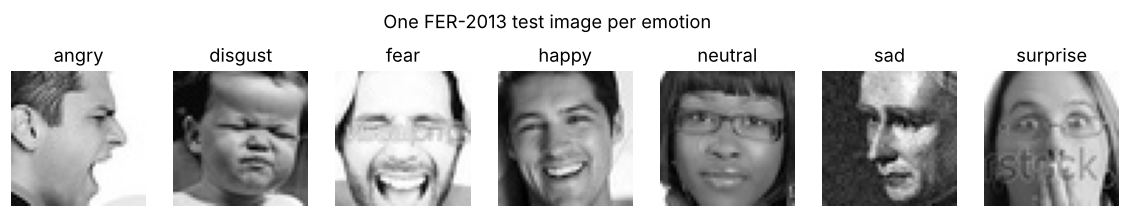

In [3]:
# A few of the face images (a small sample of FER-2013 is stored with the project)
sample_paths = sorted((DATA_DIR / "sample_faces").glob("test/*/*.jpg"))
print("Sample face images available:", len(sample_paths))

fig, axes = plt.subplots(1, 7, figsize=(13, 2.4))
for ax, path in zip(axes, sample_paths[::3]):
    ax.imshow(Image.open(path), cmap="gray")
    ax.set_title(path.parent.name)   # the folder name is the true emotion
    ax.axis("off")
fig.suptitle("One FER-2013 test image per emotion")
plt.show()

## 3. Data Preparation

### 3.1 Cleaning the Spotify tracks

The raw file has one row per *(track, genre)* pair, so a song listed under three genres appears three times. We also remove rows that cannot be used for a music recommendation. Each step is recorded so we can see how many rows it removes.

In [4]:
steps = []   # list of (description, rows remaining) filled as we clean

tracks = tracks_raw.drop(columns=["Unnamed: 0"])            # leftover index column
steps.append(("Raw file", len(tracks)))

tracks = tracks.dropna()                                    # rows with a missing title or artist
steps.append(("Drop rows with missing values", len(tracks)))

# One row per track: merge the genres of duplicated tracks into a single text column
genres = tracks.groupby("track_id")["track_genre"].agg(";".join).rename("genres")
tracks = tracks.drop_duplicates("track_id").drop(columns=["track_genre"]).merge(genres, on="track_id")
steps.append(("One row per track_id (genres merged)", len(tracks)))

# The same song can exist under several Spotify ids (album, single, compilation): keep the most popular
tracks = tracks.sort_values("popularity", ascending=False).drop_duplicates(["track_name", "artists"])
steps.append(("One row per (title, artists)", len(tracks)))

# Tracks where Spotify detected no beat cannot be used by the tempo rules
tracks = tracks[(tracks["tempo"] > 0) & (tracks["time_signature"] > 0)]
steps.append(("Drop tracks with no detected tempo", len(tracks)))

# Remove content that is not music: comedy sketches, sleep sounds, mostly spoken tracks
NON_MUSIC_GENRES = ["comedy", "sleep"]


def has_genre(genres_text, wanted):
    """True if at least one genre of the track is in the 'wanted' collection."""
    for genre in genres_text.split(";"):
        if genre in wanted:
            return True
    return False


is_non_music = tracks["genres"].apply(has_genre, wanted=NON_MUSIC_GENRES)
tracks = tracks[~is_non_music & (tracks["speechiness"] <= 0.66)]
steps.append(("Drop non-music content", len(tracks)))

for description, rows in steps:
    print(f"{description:<40} {rows:>7,} rows")

Raw file                                 114,000 rows
Drop rows with missing values            113,999 rows
One row per track_id (genres merged)      89,740 rows
One row per (title, artists)              81,343 rows
Drop tracks with no detected tempo        81,193 rows
Drop non-music content                    79,281 rows


In [5]:
# Keep the columns we need, and add a link to listen to each track
KEEP = ["track_id", "track_name", "artists", "genres", "popularity",
        "valence", "energy", "danceability", "tempo"]
tracks = tracks[KEEP].reset_index(drop=True)
tracks["spotify_url"] = "https://open.spotify.com/track/" + tracks["track_id"]

print("Clean table:", tracks.shape)
tracks[["valence", "energy", "tempo", "popularity"]].describe().round(2)

Clean table: (79281, 10)


,valence,energy,tempo,popularity
count,79281.00,79281.00,79281.00,79281.00
mean,0.47,0.64,122.86,35.37
std,0.26,0.26,29.48,19.47
min,0.00,0.00,30.32,0.00
25%,0.25,0.46,99.99,21.00
50%,0.45,0.68,122.87,36.00
75%,0.68,0.86,140.87,50.00
max,1.00,1.00,243.37,100.00


### 3.2 Regional catalogues

A first version of the recommender kept suggesting Indian film songs and Punjabi rap to listeners who had only picked American or British songs. The reason is in the data: Spotify's catalogue is worldwide, and the dataset has no language or country column.

We use two rules to tag each track with a catalogue:

1. **Genre labels.** Some of the 114 genres name a region or a language (`indian`, `k-pop`, `french`, `latin`, ...). A track with one of these genres belongs to that regional catalogue.
2. **The `hip-hop` genre.** In this dataset it mixes American rap with a large share of Indian and Pakistani rap, and nothing in the data separates them. We therefore list by hand the international hip-hop artists we know; the other tracks labelled `hip-hop` go to the South Asia catalogue. This list is a manual choice and is certainly imperfect.

Every other track is tagged `international`. The recommender will only use a regional catalogue when the listener has picked a song from it (section 4.3).

In [6]:
REGIONAL_GENRES = {
    "indian": "South Asia", "pop-film": "South Asia",
    "k-pop": "East Asia", "j-pop": "East Asia", "j-rock": "East Asia", "j-dance": "East Asia", "j-idol": "East Asia",
    "anime": "East Asia", "cantopop": "East Asia", "mandopop": "East Asia", "malay": "East Asia",
    "brazil": "Brazil", "mpb": "Brazil", "pagode": "Brazil", "samba": "Brazil", "sertanejo": "Brazil", "forro": "Brazil",
    "latin": "Latin", "latino": "Latin", "reggaeton": "Latin", "salsa": "Latin", "spanish": "Latin", "tango": "Latin",
    "french": "France", "german": "Germany", "swedish": "Sweden", "turkish": "Turkey", "iranian": "Iran",
}

# Hand-made list: artists of the dataset's "hip-hop" genre that we know as international acts
INTERNATIONAL_HIPHOP_ARTISTS = [
    "Jack Harlow", "Burna Boy", "Lizzo", "Kodak Black", "Wiz Khalifa", "Ty Dolla $ign", "Gunna", "Eminem",
    "XXXTENTACION", "Mac Miller", "Lil Nas X", "Machine Gun Kelly", "Lil Baby", "Big Sean", "Moneybagg Yo", "Drake",
    "Snoop Dogg", "Travis Scott", "DaBaby", "Kendrick Lamar", "The Kid LAROI", "Future", "Gorillaz", "J. Cole",
    "Quavo", "Kid Cudi", "Armani White", "Ali Gatie", "50 Cent", "A$AP Rocky", "Coolio", "Dr. Dre",
    "French Montana", "G-Eazy", "Ghostemane", "Sean Kingston", "Playboi Carti", "NF", "Nicki Minaj", "Offset",
    "Oliver Tree", "Masked Wolf", "Metro Boomin", "Tech N9ne", "Young Thug", "Yung Gravy", "Bizarrap", "PSY",
    "Daddy Yankee", "Don Omar", "Wisin & Yandel", "Justin Quiles", "De La Ghetto",
]


def find_region(genres_text, artists_text):
    """Return the regional catalogue of a track, or 'international'."""
    genres = genres_text.split(";")
    for genre in genres:
        if genre in REGIONAL_GENRES:
            return REGIONAL_GENRES[genre]
    main_artist = artists_text.split(";")[0]
    if "hip-hop" in genres and main_artist not in INTERNATIONAL_HIPHOP_ARTISTS:
        return "South Asia"
    return "international"


regions = []
for genres_text, artists_text in zip(tracks["genres"], tracks["artists"]):
    regions.append(find_region(genres_text, artists_text))
tracks["region"] = regions

print("Tracks labelled hip-hop:", int(tracks["genres"].apply(has_genre, wanted=["hip-hop"]).sum()),
      "| of which tagged South Asia:", int((tracks["genres"].apply(has_genre, wanted=["hip-hop"]) & (tracks["region"] == "South Asia")).sum()))
tracks["region"].value_counts()

Tracks labelled hip-hop: 711 | of which tagged South Asia: 489


,count
region,
international,56123
East Asia,7613
Brazil,5037
Latin,3813
South Asia,2256
France,960
Iran,951
Turkey,916
Sweden,835


### 3.3 Preparing the face predictions

The predictions file is already tidy. We check that the 7 probabilities of each image sum to 1, and add two helper columns: whether the prediction is correct, and how confident the classifier was.

In [7]:
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
PROBA_COLUMNS = ["p_" + emotion for emotion in EMOTIONS]

sums = faces[PROBA_COLUMNS].sum(axis=1)
print("Probabilities sum to 1 for every image:", bool(((sums - 1).abs() < 0.01).all()))
print("Missing values in the file:", int(faces.isna().sum().sum()))

faces["correct"] = faces["true_emotion"] == faces["predicted_emotion"]
faces["confidence"] = faces[PROBA_COLUMNS].max(axis=1)

print(f"Classifier accuracy on the test images: {faces['correct'].mean():.1%}")
faces["true_emotion"].value_counts()

Probabilities sum to 1 for every image: True
Missing values in the file: 0
Classifier accuracy on the test images: 59.5%


,count
true_emotion,
happy,1774
sad,1247
neutral,1233
fear,1024
angry,958
surprise,831
disgust,111


## 4. Programming Logic

### 4.1 From emotion probabilities to a point on the map

Each emotion gets a position on the (valence, energy) map, on Spotify's 0-to-1 scale. **These coordinates are our modelling choice**, inspired by Russell's circumplex model: joy is positive and fairly energetic, anger is negative and very energetic, sadness is negative and calm, neutral sits in the middle.

A face is rarely 100% one emotion. Instead of using only the top label, we take the average of the 7 positions, weighted by the probabilities. A face that is 60% sad and 40% neutral lands between the two.

In [8]:
# (valence, energy) position of each emotion, on Spotify's 0-1 scale
EMOTION_COORDS = {
    "happy":    (0.85, 0.70),
    "surprise": (0.65, 0.85),
    "angry":    (0.20, 0.90),
    "fear":     (0.15, 0.75),
    "disgust":  (0.20, 0.60),
    "sad":      (0.15, 0.25),
    "neutral":  (0.50, 0.45),
}


def emotion_to_point(probabilities):
    """Convert a dictionary {emotion: probability} into one (valence, energy) point."""
    valence, energy = 0.0, 0.0
    for emotion, probability in probabilities.items():
        emotion_valence, emotion_energy = EMOTION_COORDS[emotion]
        valence += probability * emotion_valence
        energy += probability * emotion_energy
    return valence, energy


def face_probabilities(face_row):
    """Extract the 7 probabilities of one row of the 'faces' table as a dictionary."""
    probabilities = {}
    for emotion in EMOTIONS:
        probabilities[emotion] = face_row["p_" + emotion]
    return probabilities


example = faces.iloc[0]
print("True emotion:", example["true_emotion"], "| predicted:", example["predicted_emotion"])
print("Probabilities:", {e: round(float(p), 2) for e, p in face_probabilities(example).items()})
print("Point on the map (valence, energy):", tuple(round(float(x), 2) for x in emotion_to_point(face_probabilities(example))))

True emotion: angry | predicted: angry
Probabilities: {'angry': 0.56, 'disgust': 0.06, 'fear': 0.17, 'happy': 0.09, 'neutral': 0.01, 'sad': 0.08, 'surprise': 0.02}
Point on the map (valence, energy): (0.26, 0.78)


### 4.2 Driving rules

In a car, matching the driver's mood is not always a good idea: angry music for an angry driver can make things worse. Simulator studies (Brodsky, 2001) found that faster music goes with higher speed and more traffic violations, and a real-road study on long drives found medium-tempo music best for staying attentive. Brodsky's tempo bands are: slow 40-70 BPM, medium 85-110 BPM, fast 120-140 BPM.

So in *drive* mode we first detect a **risk** from the face, then move the music target towards a safer state and restrict the tempo.

**Detecting the risk.** Emotions that lead to the same driving risk are grouped, and their probabilities are added up. The group with the highest total wins. We use the probabilities here, not the averaged point: when the classifier hesitates, the averaged point drifts towards the centre of the map and would hide the risk.

| Risk | Emotions added up | Music target in drive mode |
|---|---|---|
| Tension (speed, aggressive driving) | angry + fear + disgust | Calmer and more positive, tempo 60-100 BPM |
| Excitement (over-confidence) | happy + surprise | Same positivity, energy capped at 0.60, tempo below 120 BPM |
| Low alertness | sad | More positive, medium energy, medium tempo 85-110 BPM |
| None | neutral | Unchanged, tempo below 120 BPM |

**Moving the target.** For tension and low alertness, the music target moves 70% of the way from the driver's current point to a "safe point". Starting from where the listener is and moving gradually is the idea behind the *iso principle* used in music therapy. The safe points, the 70% and the tempo ranges are our own choices.

FER-2013 has no "drowsy" label, so this prototype cannot detect sleepiness itself; low alertness is approximated by a sad expression.

In [9]:
RISK_GROUPS = {
    "tension":       ["angry", "fear", "disgust"],
    "excitement":    ["happy", "surprise"],
    "low alertness": ["sad"],
    "none":          ["neutral"],
}
SAFE_POINTS = {"tension": (0.60, 0.35), "low alertness": (0.60, 0.60)}     # (valence, energy)
TEMPO_RANGES = {"tension": (60, 100), "excitement": (60, 120), "low alertness": (85, 110), "none": (60, 120)}
STEER = 0.7   # how far the music target moves towards the safe point (0 = not at all, 1 = all the way)


def detect_driving_risk(probabilities):
    """Add up the probabilities of the emotions behind each risk and return the most likely risk."""
    best_risk, best_score = "none", 0.0
    for risk, emotions in RISK_GROUPS.items():
        score = 0.0
        for emotion in emotions:
            score += probabilities[emotion]
        if score > best_score:
            best_risk, best_score = risk, score
    return best_risk


def driving_target(probabilities):
    """Return (risk, music target point, allowed tempo range) for a driver with these probabilities."""
    valence, energy = emotion_to_point(probabilities)
    risk = detect_driving_risk(probabilities)
    if risk == "tension" or risk == "low alertness":
        safe_valence, safe_energy = SAFE_POINTS[risk]
        valence = valence + STEER * (safe_valence - valence)
        energy = energy + STEER * (safe_energy - energy)
    elif risk == "excitement":
        energy = min(energy, 0.60)
    return risk, (round(float(valence), 2), round(float(energy), 2)), TEMPO_RANGES[risk]


# What the rules do for a face that is 100% one emotion
for name in EMOTIONS:
    pure = {emotion: (1.0 if emotion == name else 0.0) for emotion in EMOTIONS}
    print(f"{name:<8} at {EMOTION_COORDS[name]} -> {driving_target(pure)}")

angry    at (0.2, 0.9) -> ('tension', (0.48, 0.52), (60, 100))
disgust  at (0.2, 0.6) -> ('tension', (0.48, 0.42), (60, 100))
fear     at (0.15, 0.75) -> ('tension', (0.46, 0.47), (60, 100))
happy    at (0.85, 0.7) -> ('excitement', (0.85, 0.6), (60, 120))
neutral  at (0.5, 0.45) -> ('none', (0.5, 0.45), (60, 120))
sad      at (0.15, 0.25) -> ('low alertness', (0.46, 0.49), (85, 110))
surprise at (0.65, 0.85) -> ('excitement', (0.65, 0.6), (60, 120))


### 4.3 Personal taste

Two people with the same expression should not get the same song. A listener tells us a few songs they like; we look them up in the dataset and count their genres. The genres that come up most often form the taste profile, and recommendations are then restricted to those genres.

The profile also records the regional catalogues (section 3.2) of the liked songs. A listener who likes a French song will get French songs; a listener who picked none will not.

In [10]:
def find_track(title):
    """Find a song by title (exact match first, then partial). Returns the most popular match, or None."""
    title = title.lower().strip()
    names = tracks["track_name"].str.lower()
    matches = tracks[names == title]
    if len(matches) == 0:
        matches = tracks[names.str.contains(title, regex=False)]
    if len(matches) == 0:
        return None
    return matches.sort_values("popularity", ascending=False).iloc[0]


def build_taste_profile(liked_titles):
    """Build a taste profile from a list of song titles the listener likes."""
    genre_counts = {}
    regions = set()
    found, missing = [], []
    for title in liked_titles:
        track = find_track(title)
        if track is None:
            missing.append(title)
            continue
        found.append(f"{track['track_name']} - {track['artists']}")
        if track["region"] != "international":
            regions.add(track["region"])
        for genre in track["genres"].split(";"):
            genre_counts[genre] = genre_counts.get(genre, 0) + 1

    # Keep the genres cited at least half as often as the listener's top genre
    genres = set()
    if len(genre_counts) > 0:
        top_count = max(genre_counts.values())
        for genre, count in genre_counts.items():
            if count >= top_count / 2:
                genres.add(genre)
    return {"genres": genres, "regions": regions, "found": found, "missing": missing}


rap_fan = build_taste_profile(["HUMBLE.", "SICKO MODE", "God's Plan", "a song that does not exist"])
rock_fan = build_taste_profile(["Bohemian Rhapsody", "Back In Black", "Smells Like Teen Spirit"])
french_fan = build_taste_profile(["Tourner Dans Le Vide", "Midnight City"])
for name, profile in [("Rap fan", rap_fan), ("Rock fan", rock_fan), ("French fan", french_fan)]:
    print(f"{name}: genres = {sorted(profile['genres'])} | regional catalogues = {sorted(profile['regions'])}")
    print(f"   found = {profile['found']} | not in the dataset = {profile['missing']}")

Rap fan: genres = ['hip-hop'] | regional catalogues = []
   found = ['HUMBLE. - Kendrick Lamar', 'SICKO MODE - Travis Scott', "God's Plan - Drake"] | not in the dataset = ['a song that does not exist']
Rock fan: genres = ['rock'] | regional catalogues = []
   found = ['Bohemian Rhapsody - Queen', 'Back In Black - AC/DC', 'Smells Like Teen Spirit - Nirvana'] | not in the dataset = []
French fan: genres = ['french', 'indie'] | regional catalogues = ['France']
   found = ['Tourner Dans Le Vide - Indila', 'Midnight City - M83'] | not in the dataset = []


### 4.4 The recommendation function

`recommend` ties everything together:

1. convert the probabilities into a target point;
2. in *drive* mode, apply the driving rules (new target, tempo range);
3. keep the international catalogue, plus the regional catalogues the listener has shown interest in;
4. keep only the listener's genres, if a taste profile is given;
5. look for well-known songs close to the target, in successive steps: first hits (popularity of at least 70 out of 100) within a distance of 0.15 on the map, then songs with a popularity of at least 50, then the same two levels a little further away (0.25), and only then lesser-known songs, stopping as soon as enough different artists are found;
6. return the closest songs, at most one per artist.

Step 4 is skipped when it would leave too few songs to choose from.

In [11]:
# Search steps, tried in order: (minimum popularity, maximum distance to the target)
SEARCH_STEPS = [(70, 0.15), (50, 0.15), (70, 0.25), (50, 0.25), (0, 0.15)]


def recommend(probabilities, mode="match", taste=None, n=5, exclude=()):
    """Recommend n songs for a face.

    probabilities : dictionary {emotion: probability} from the classifier
    mode          : "match" (music that fits the mood) or "drive" (music that steers towards a safe state)
    taste         : optional taste profile from build_taste_profile()
    exclude       : track ids to skip (songs already played)
    """
    valence, energy = emotion_to_point(probabilities)
    candidates = tracks[~tracks["track_id"].isin(exclude)]

    if mode == "drive":
        risk, (valence, energy), (tempo_min, tempo_max) = driving_target(probabilities)
        candidates = candidates[candidates["tempo"].between(tempo_min, tempo_max)]

    allowed_regions = {"international"}
    if taste is not None:
        allowed_regions = allowed_regions | taste["regions"]
    candidates = candidates[candidates["region"].isin(allowed_regions)]

    if taste is not None and len(taste["genres"]) > 0:
        in_taste = candidates["genres"].apply(has_genre, wanted=taste["genres"])
        if candidates.loc[in_taste, "artists"].nunique() >= n:      # only filter if enough songs remain
            candidates = candidates[in_taste]

    # Distance between every candidate song and the target point
    distance = np.sqrt((candidates["valence"] - valence) ** 2 + (candidates["energy"] - energy) ** 2)
    candidates = candidates.assign(distance=distance.round(3))

    # Prefer well-known songs close to the target; relax the requirements step by step
    for min_popularity, max_distance in SEARCH_STEPS:
        close = candidates[(candidates["popularity"] >= min_popularity) & (candidates["distance"] <= max_distance)]
        if close["artists"].nunique() >= n:
            break
    if close["artists"].nunique() < n:      # still not enough: take the closest songs overall
        close = candidates

    best = close.sort_values("distance").drop_duplicates("artists").head(n)
    return best[["track_id", "track_name", "artists", "genres", "valence", "energy", "tempo", "popularity", "distance"]]


SHOW = ["track_name", "artists", "genres", "valence", "energy", "tempo", "popularity", "distance"]

# Example: a face the classifier reads as clearly angry
angry_face = faces[faces["predicted_emotion"] == "angry"].sort_values("confidence", ascending=False).iloc[0]
angry_probabilities = face_probabilities(angry_face)
print("Image:", angry_face["image"], "| confidence:", round(float(angry_face["confidence"]), 2))
print("Point on the map:", tuple(round(float(x), 2) for x in emotion_to_point(angry_probabilities)))

print("\nMode 'match' - music that fits the mood:")
recommend(angry_probabilities, mode="match")[SHOW]

Image: test/angry/PrivateTest_56780735.jpg | confidence: 0.86
Point on the map: (0.24, 0.87)

Mode 'match' - music that fits the mood:


,track_name,artists,genres,valence,energy,tempo,popularity,distance
73,505,Arctic Monkeys,garage;indie;rock,0.248,0.866,140.266,88,0.009
238,Numb,Linkin Park,alternative;grunge;metal,0.243,0.863,110.018,83,0.009
961,Don't Call Me Up,Mabel,edm;house,0.234,0.881,98.994,77,0.011
2235,Fear of the Dark - 2015 Remaster,Iron Maiden,hard-rock;metal,0.227,0.866,109.825,72,0.015
1913,For Whom The Bell Tolls - Remastered,Metallica,hard-rock;metal,0.249,0.858,117.897,73,0.016


In [12]:
print("Drive mode decision (risk, music target, tempo range):", driving_target(angry_probabilities))
print("\nMode 'drive' - music that calms the driver down:")
recommend(angry_probabilities, mode="drive")[SHOW]

Drive mode decision (risk, music target, tempo range): ('tension', (0.49, 0.51), (60, 100))

Mode 'drive' - music that calms the driver down:


,track_name,artists,genres,valence,energy,tempo,popularity,distance
631,We Will Rock You - Remastered 2011,Queen,rock,0.475,0.497,81.308,79,0.020
82,I'm Not The Only One,Sam Smith,dance;dance,0.493,0.485,82.001,88,0.025
2423,The Look,Metronomy,electronic,0.504,0.535,84.947,71,0.029
955,It Ain't Me (with Selena Gomez),Kygo;Selena Gomez,dance;edm;house,0.515,0.533,99.968,77,0.034
521,IDGAF,Dua Lipa,dance,0.510,0.544,97.028,80,0.039


In [13]:
print("Mode 'drive' for the rap fan - same face, same rules, different taste:")
recommend(angry_probabilities, mode="drive", taste=rap_fan)[SHOW]

Mode 'drive' for the rap fan - same face, same rules, different taste:


,track_name,artists,genres,valence,energy,tempo,popularity,distance
704,Life Goes On,Oliver Tree,alternative;hip-hop,0.569,0.490,79.982,79,0.081
582,WITHOUT YOU,The Kid LAROI,hip-hop,0.467,0.413,93.005,80,0.100
56,Gangsta's Paradise,Coolio;L.V.,funk;hip-hop,0.386,0.514,79.975,89,0.104
251,SAD!,XXXTENTACION,emo;hip-hop,0.473,0.613,75.023,83,0.104
564,It's You,Ali Gatie,hip-hop;pop,0.397,0.463,95.971,80,0.104


In [14]:
print("Mode 'drive' for the rock fan:")
recommend(angry_probabilities, mode="drive", taste=rock_fan)[SHOW]

Mode 'drive' for the rock fan:


,track_name,artists,genres,valence,energy,tempo,popularity,distance
631,We Will Rock You - Remastered 2011,Queen,rock,0.475,0.497,81.308,79,0.020
1189,You're Beautiful,James Blunt,rock,0.454,0.479,81.998,76,0.048
1272,River,Bishop Briggs,electro;rock,0.545,0.477,62.507,75,0.064
823,Homage,Mild High Club,garage;indie;psych-rock;rock,0.415,0.465,73.369,78,0.087
75,Do I Wanna Know?,Arctic Monkeys,garage;indie;rock,0.405,0.532,85.030,88,0.088


### 4.5 Applying the logic to every face

We loop over the 7,178 test faces to compute each one's point on the map and its driving risk. This gives a summary of what the system would do across the whole test set.

In [15]:
points_valence, points_energy, risks = [], [], []
for _, face_row in faces.iterrows():
    probabilities = face_probabilities(face_row)
    valence, energy = emotion_to_point(probabilities)
    points_valence.append(valence)
    points_energy.append(energy)
    risks.append(detect_driving_risk(probabilities))

faces["point_valence"] = points_valence
faces["point_energy"] = points_energy
faces["risk"] = risks

# Share of each detected risk, by true emotion (each row sums to 1)
RISKS = ["tension", "excitement", "low alertness", "none"]
risk_by_emotion = pd.crosstab(faces["true_emotion"], faces["risk"], normalize="index").reindex(columns=RISKS).round(2)
risk_by_emotion

risk,tension,excitement,low alertness,none
true_emotion,,,,
angry,0.77,0.06,0.04,0.13
disgust,0.94,0.03,0.00,0.04
fear,0.62,0.17,0.10,0.10
happy,0.06,0.88,0.01,0.06
neutral,0.24,0.08,0.06,0.61
sad,0.47,0.07,0.25,0.21
surprise,0.18,0.80,0.00,0.02


In [16]:
# Where do the faces land on the map, on average, for each true emotion?
faces.groupby("true_emotion")[["point_valence", "point_energy"]].mean().round(2)

,point_valence,point_energy
true_emotion,,
angry,0.31,0.67
disgust,0.26,0.70
fear,0.33,0.65
happy,0.76,0.68
neutral,0.41,0.53
sad,0.32,0.56
surprise,0.53,0.80


### 4.6 A simulated drive

A driver's expression changes during a trip. We simulate a short drive as a sequence of faces: at each step the system reads the face, detects the risk, and adds one new song to the playlist, never repeating a song.

In [17]:
def most_confident_face(emotion):
    """Return the test face the classifier most confidently assigns to this emotion."""
    subset = faces[faces["predicted_emotion"] == emotion]
    return subset.sort_values("confidence", ascending=False).iloc[0]


def simulate_drive(emotion_sequence, taste=None):
    """Build a playlist, one song per step of the drive."""
    playlist = []
    played_ids = []
    for step, emotion in enumerate(emotion_sequence, start=1):
        probabilities = face_probabilities(most_confident_face(emotion))
        risk = detect_driving_risk(probabilities)
        song = recommend(probabilities, mode="drive", taste=taste, n=1, exclude=played_ids).iloc[0]
        played_ids.append(song["track_id"])
        playlist.append({
            "step": step, "face": emotion, "risk": risk,
            "song": song["track_name"], "artists": song["artists"],
            "tempo": round(float(song["tempo"])), "energy": song["energy"], "valence": song["valence"],
        })
    return pd.DataFrame(playlist)


drive = simulate_drive(["neutral", "happy", "angry", "angry", "sad", "neutral"], taste=rock_fan)
drive

,step,face,risk,song,artists,tempo,energy,valence
0,1,neutral,none,I Want To Break Free,Queen,109,0.414,0.502
1,2,happy,excitement,Why'd You Only Call Me When You're High?,Arctic Monkeys,92,0.631,0.800
2,3,angry,tension,We Will Rock You - Remastered 2011,Queen,81,0.497,0.475
3,4,angry,tension,You're Beautiful,James Blunt,82,0.479,0.454
4,5,sad,low alertness,Do I Wanna Know?,Arctic Monkeys,85,0.532,0.405
5,6,neutral,none,I Wanna Be Yours,Arctic Monkeys,68,0.417,0.479


### 4.7 Sanity check: do the Spotify scores behave like emotions?

First, a look at well-known songs in the four corners of the map. Anyone who knows these songs can judge whether the position makes sense.

In [18]:
CORNERS = {
    "positive and intense": (0.90, 0.85),
    "negative and intense": (0.15, 0.90),
    "negative and calm":    (0.15, 0.20),
    "positive and calm":    (0.80, 0.35),
}
for label, (valence, energy) in CORNERS.items():
    distance = np.sqrt((tracks["valence"] - valence) ** 2 + (tracks["energy"] - energy) ** 2)
    corner = tracks[distance <= 0.10].sort_values("popularity", ascending=False).drop_duplicates("artists").head(4)
    print(f"{label} (valence {valence}, energy {energy}):")
    for _, song in corner.iterrows():
        print(f"    {song['track_name']} - {song['artists']}")

positive and intense (valence 0.9, energy 0.85):
    I Ain't Worried - OneRepublic
    Super Freaky Girl - Nicki Minaj
    Woman - Doja Cat
    Bad Decisions (with BTS & Snoop Dogg) - benny blanco;BTS;Snoop Dogg
negative and intense (valence 0.15, energy 0.9):
    Till I Collapse - Eminem;Nate Dogg
    Mr. Brightside - The Killers
    PUNTO 40 - Rauw Alejandro;Baby Rasta
    Youngblood - 5 Seconds of Summer
negative and calm (valence 0.15, energy 0.2):
    Something in the Orange - Zach Bryan
    Revenge - XXXTENTACION
    everything i wanted - Billie Eilish
    Fourth of July - Sufjan Stevens
positive and calm (valence 0.8, energy 0.35):
    Africa - TOTO
    Chaand Baaliyan - Aditya A
    Suspicious Minds - Elvis Presley
    Another Brick in the Wall, Pt. 2 - Pink Floyd


Second, a warning about labels. The dataset contains four genres named after moods: `happy`, `party`, `chill` and `sad`. It is tempting to use them as ready-made mood labels, so we measured where they sit on the map.

In [19]:
MOOD_GENRES = ["happy", "party", "chill", "sad"]
for genre in MOOD_GENRES:
    subset = tracks[tracks["genres"].apply(has_genre, wanted=[genre])]
    top_artists = subset.sort_values("popularity", ascending=False)["artists"].drop_duplicates().head(3).tolist()
    print(f"genre '{genre}': {len(subset):>4} tracks | mean valence {subset['valence'].mean():.2f} "
          f"| mean energy {subset['energy'].mean():.2f} | e.g. {top_artists}")

genre 'happy':  953 tracks | mean valence 0.33 | mean energy 0.91 | e.g. ['The Prophet', '2 Brothers On The 4th Floor', 'Darren Styles']
genre 'party':  795 tracks | mean valence 0.68 | mean energy 0.87 | e.g. ['DJ Robin;Schürze', 'Die Zipfelbuben;DJ Cashi', 'Tream;treamiboii;HBz']
genre 'chill':  934 tracks | mean valence 0.40 | mean energy 0.42 | e.g. ['Tom Odell', 'dhruv', '80purppp']
genre 'sad':  961 tracks | mean valence 0.42 | mean energy 0.46 | e.g. ['Cheriimoya;Sierra Kidd', 'Powfu;beabadoobee', 'Kina;Snøw']


`party` is positive and intense, and `chill` and `sad` are both low in energy, as expected. But `happy` has a **low** valence and a very high energy: on Spotify this genre is "happy hardcore", a fast electronic style, not cheerful music. `sad` and `chill` are also almost at the same place. Genre names are therefore not reliable mood labels, which is why the recommender relies on the valence and energy scores of each song instead.

## 5. Visualization

### 5.1 The face data: how many images per emotion, and how well each is recognised

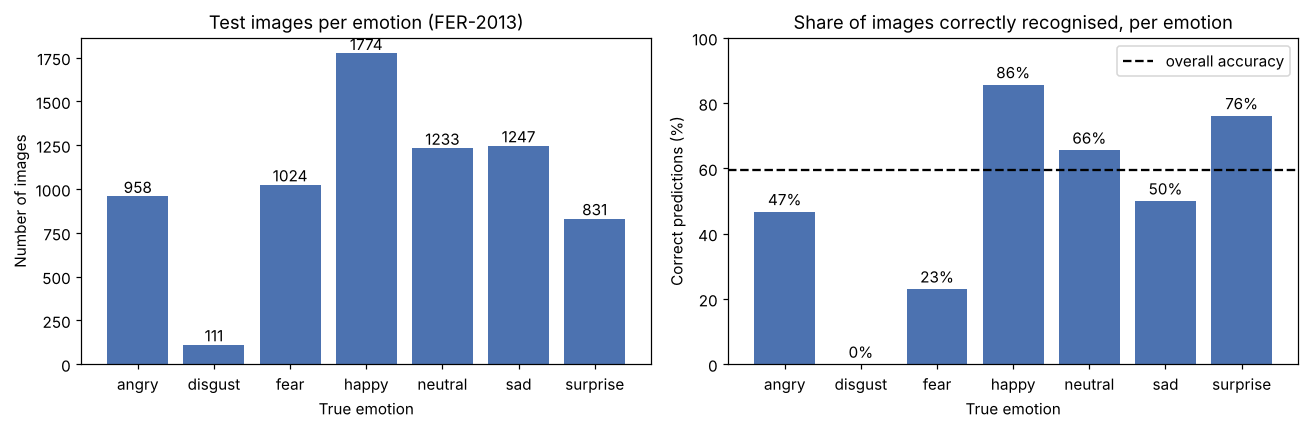

In [20]:
counts = faces["true_emotion"].value_counts().reindex(EMOTIONS)
accuracy = faces.groupby("true_emotion")["correct"].mean().reindex(EMOTIONS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(counts.index, counts.values, color="#4C72B0")
ax1.set_title("Test images per emotion (FER-2013)")
ax1.set_xlabel("True emotion")
ax1.set_ylabel("Number of images")
for x, value in enumerate(counts.values):
    ax1.text(x, value + 20, str(value), ha="center")

ax2.bar(accuracy.index, accuracy.values * 100, color="#4C72B0")
ax2.axhline(faces["correct"].mean() * 100, color="black", linestyle="--", label="overall accuracy")
ax2.set_title("Share of images correctly recognised, per emotion")
ax2.set_xlabel("True emotion")
ax2.set_ylabel("Correct predictions (%)")
ax2.set_ylim(0, 100)
for x, value in enumerate(accuracy.values):
    ax2.text(x, value * 100 + 2, f"{value:.0%}", ha="center")
ax2.legend()

plt.tight_layout()
plt.show()

### 5.2 Confusion matrix of the classifier

Each row is a true emotion; each cell shows which emotion the classifier answered, as a share of the row.

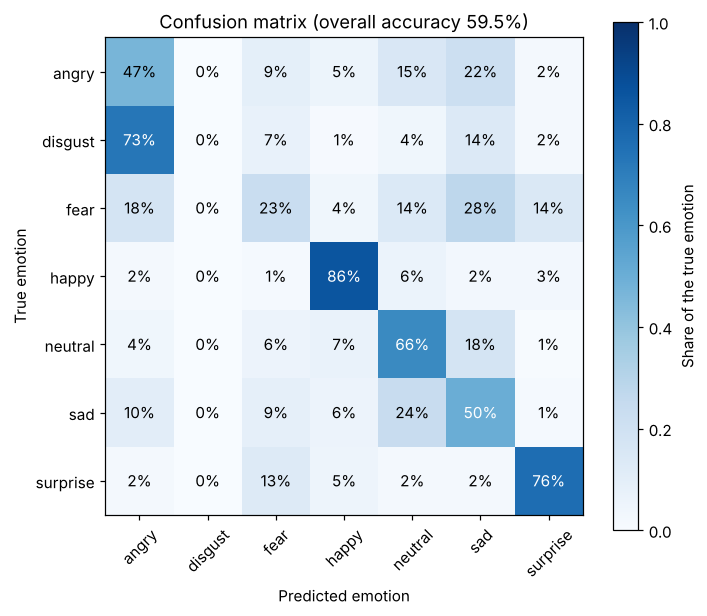

In [21]:
confusion = pd.crosstab(faces["true_emotion"], faces["predicted_emotion"], normalize="index")
confusion = confusion.reindex(index=EMOTIONS, columns=EMOTIONS, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(confusion.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(7))
ax.set_xticklabels(EMOTIONS, rotation=45)
ax.set_yticks(range(7))
ax.set_yticklabels(EMOTIONS)
ax.set_xlabel("Predicted emotion")
ax.set_ylabel("True emotion")
ax.set_title(f"Confusion matrix (overall accuracy {faces['correct'].mean():.1%})")
for i in range(7):
    for j in range(7):
        value = confusion.values[i, j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", color="white" if value > 0.5 else "black")
fig.colorbar(image, ax=ax, label="Share of the true emotion")
plt.show()

### 5.3 The emotional map: songs and emotions in the same space

Every song is a point (valence, energy); darker areas contain more songs. The red dots are the 7 emotion positions chosen in section 4.1. Each blue square is where the test faces of that true emotion land on average: the line shows how far classifier uncertainty pulls them towards the centre.

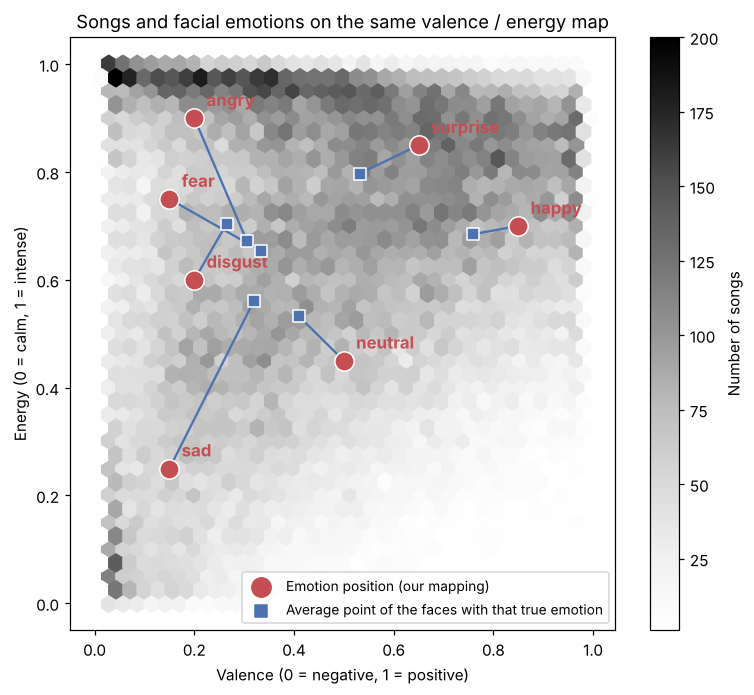

In [22]:
fig, ax = plt.subplots(figsize=(8, 7))
hexes = ax.hexbin(tracks["valence"], tracks["energy"], gridsize=35, cmap="Greys", mincnt=1)
fig.colorbar(hexes, ax=ax, label="Number of songs")

for emotion, (valence, energy) in EMOTION_COORDS.items():
    ax.scatter(valence, energy, s=160, color="#C44E52", edgecolor="white", zorder=3)
    ax.annotate(emotion, (valence, energy), xytext=(8, 8), textcoords="offset points",
                fontsize=11, fontweight="bold", color="#C44E52")

# Where the test faces actually land, on average, for each true emotion
landing = faces.groupby("true_emotion")[["point_valence", "point_energy"]].mean()
for emotion, row in landing.iterrows():
    ax.plot([EMOTION_COORDS[emotion][0], row["point_valence"]], [EMOTION_COORDS[emotion][1], row["point_energy"]],
            color="#4C72B0", linewidth=1.5, zorder=2)
    ax.scatter(row["point_valence"], row["point_energy"], s=70, marker="s", color="#4C72B0", edgecolor="white", zorder=3)

ax.scatter([], [], s=160, color="#C44E52", label="Emotion position (our mapping)")
ax.scatter([], [], s=70, marker="s", color="#4C72B0", label="Average point of the faces with that true emotion")
ax.set_xlabel("Valence (0 = negative, 1 = positive)")
ax.set_ylabel("Energy (0 = calm, 1 = intense)")
ax.set_title("Songs and facial emotions on the same valence / energy map")
ax.legend(loc="lower right", fontsize=9)
plt.show()

### 5.4 From a face to a song

For sample faces: the true emotion, what the classifier predicted, and one song in each mode. A song is never shown twice in the grid, as in a playlist.

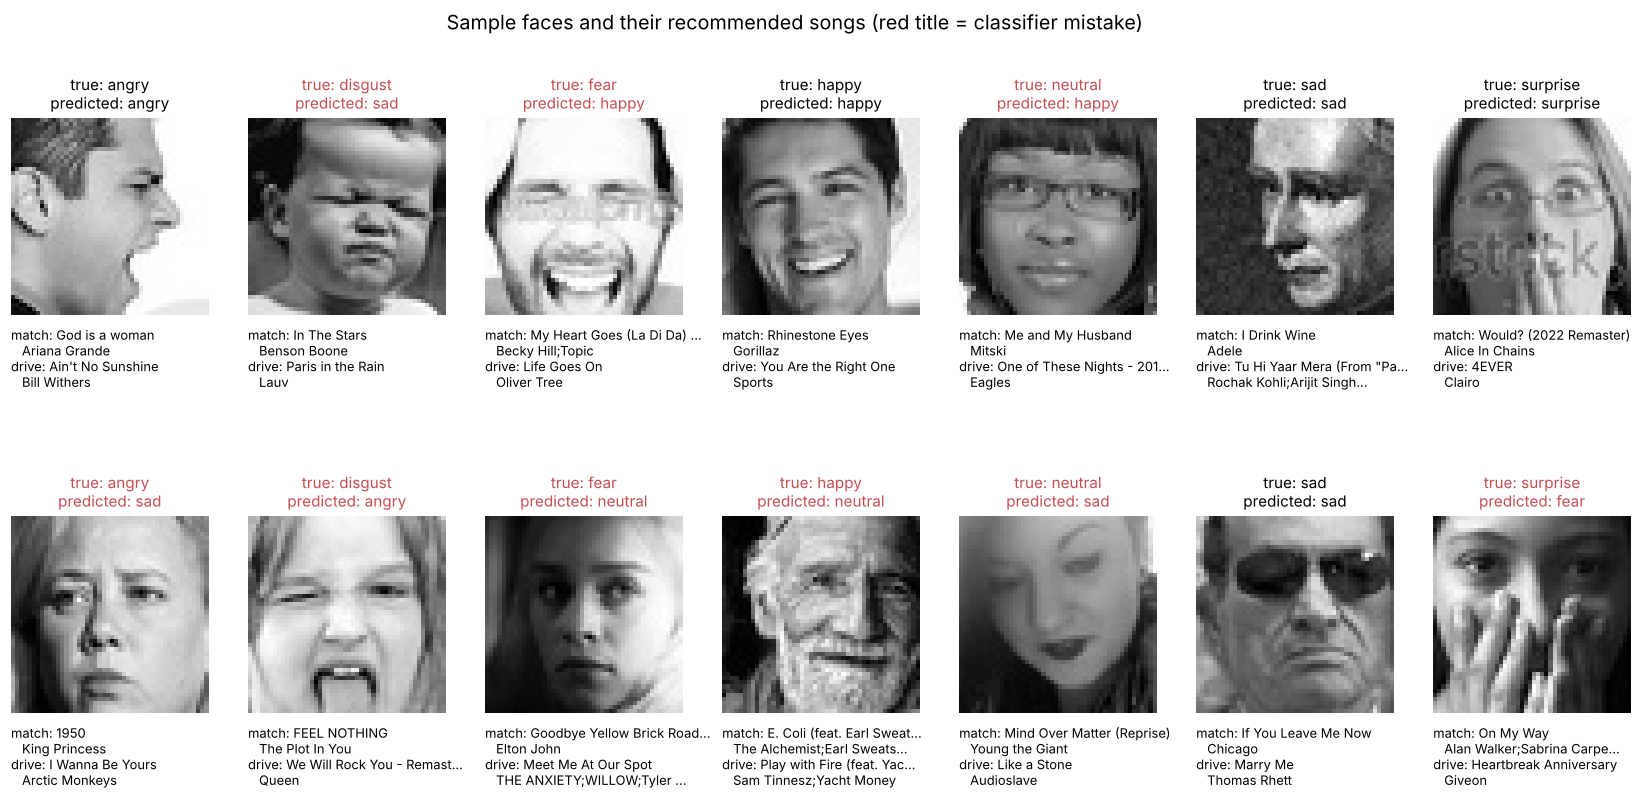

In [23]:
def short(text, limit=26):
    """Shorten long titles so they fit under an image."""
    return text if len(text) <= limit else text[: limit - 1] + "…"


grid_paths = sample_paths[::3] + sample_paths[1::3]      # two faces per emotion
shown_ids = []                                            # songs already shown, to avoid repeats in the grid
fig, axes = plt.subplots(2, 7, figsize=(19, 7.6))
for ax, path in zip(axes.flat, grid_paths):
    image_key = path.relative_to(DATA_DIR / "sample_faces").as_posix()
    face_row = faces[faces["image"] == image_key].iloc[0]
    probabilities = face_probabilities(face_row)
    match_song = recommend(probabilities, mode="match", n=1, exclude=shown_ids).iloc[0]
    shown_ids.append(match_song["track_id"])
    drive_song = recommend(probabilities, mode="drive", n=1, exclude=shown_ids).iloc[0]
    shown_ids.append(drive_song["track_id"])

    ax.imshow(Image.open(path), cmap="gray")
    ax.axis("off")
    ax.set_title(f"true: {face_row['true_emotion']}\npredicted: {face_row['predicted_emotion']}",
                 fontsize=10, color="black" if face_row["correct"] else "#C44E52")
    caption = (f"match: {short(match_song['track_name'])}\n   {short(match_song['artists'])}\n"
               f"drive: {short(drive_song['track_name'])}\n   {short(drive_song['artists'])}")
    ax.text(0.0, -0.06, caption, transform=ax.transAxes, fontsize=8.5, va="top", ha="left")
fig.suptitle("Sample faces and their recommended songs (red title = classifier mistake)", fontsize=13)
plt.subplots_adjust(hspace=0.62, top=0.88)
plt.show()

### 5.5 What drive mode changes

For a random sample of 400 faces, we compare the top recommended song in *match* mode and in *drive* mode, grouped by the detected risk.

Faces per detected risk in the sample: {'excitement': 151, 'tension': 143, 'none': 74, 'low alertness': 32}


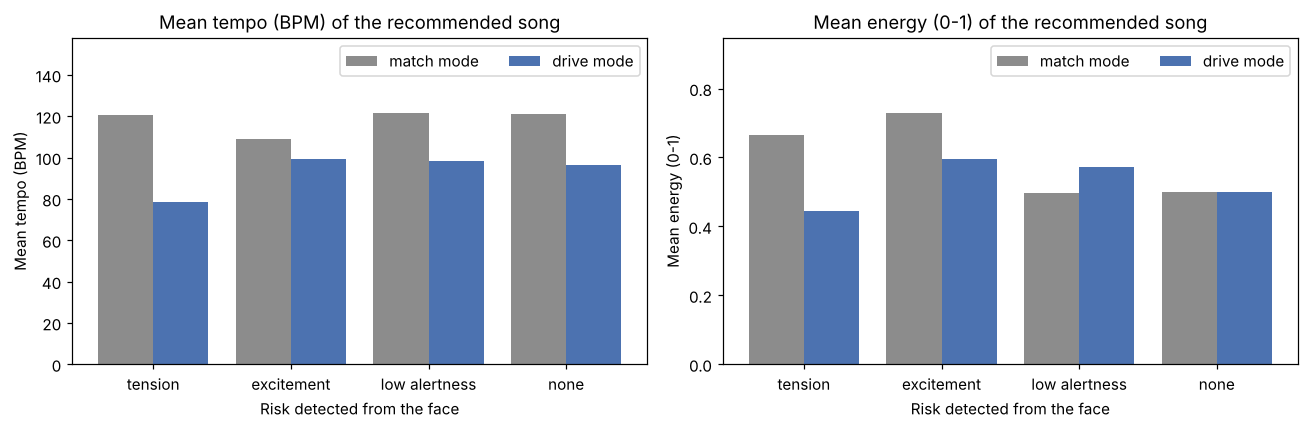

tempo         energy      
mode           drive   match  drive match
risk                                     
tension        78.30  120.68   0.44  0.67
excitement     99.46  108.88   0.60  0.73
low alertness  98.10  121.43   0.57  0.50
none           96.20  120.92   0.50  0.50

In [24]:
sample = faces.sample(400, random_state=1)
rows = []
for _, face_row in sample.iterrows():
    probabilities = face_probabilities(face_row)
    for mode in ["match", "drive"]:
        song = recommend(probabilities, mode=mode, n=1).iloc[0]
        rows.append({"risk": face_row["risk"], "mode": mode, "tempo": song["tempo"], "energy": song["energy"]})
comparison = pd.DataFrame(rows)

means = comparison.groupby(["risk", "mode"])[["tempo", "energy"]].mean().unstack("mode").reindex(RISKS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(len(RISKS))
for ax, feature, label in [(ax1, "tempo", "Mean tempo (BPM)"), (ax2, "energy", "Mean energy (0-1)")]:
    ax.bar(positions - 0.2, means[(feature, "match")], width=0.4, color="#8C8C8C", label="match mode")
    ax.bar(positions + 0.2, means[(feature, "drive")], width=0.4, color="#4C72B0", label="drive mode")
    ax.set_xticks(positions)
    ax.set_xticklabels(RISKS)
    ax.set_xlabel("Risk detected from the face")
    ax.set_ylabel(label)
    ax.set_title(f"{label} of the recommended song")
    ax.set_ylim(0, means[feature].max().max() * 1.3)      # leave room for the legend
    ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

print("Faces per detected risk in the sample:", sample["risk"].value_counts().to_dict())
means.round(2)

## 6. Conclusion

In [25]:
# Key numbers used in the conclusion (recomputed from the data each time the notebook runs)
accuracy_by_emotion = faces.groupby("true_emotion")["correct"].mean().sort_values(ascending=False)
print(f"Songs after cleaning            : {len(tracks):,} (from {len(tracks_raw):,} raw rows)")
print(f"Test faces                      : {len(faces):,}")
print(f"Classifier accuracy             : {faces['correct'].mean():.1%}")
print(f"Best recognised emotion         : {accuracy_by_emotion.index[0]} ({accuracy_by_emotion.iloc[0]:.0%})")
print(f"Worst recognised emotion        : {accuracy_by_emotion.index[-1]} ({accuracy_by_emotion.iloc[-1]:.0%})")
print(f"Faces flagged with a driving risk: {(faces['risk'] != 'none').mean():.0%}")

Songs after cleaning            : 79,281 (from 114,000 raw rows)
Test faces                      : 7,178
Classifier accuracy             : 59.5%
Best recognised emotion         : happy (86%)
Worst recognised emotion        : disgust (0%)
Faces flagged with a driving risk: 81%


**What we built.** A complete chain from a face image to a song: a classifier reads 7 emotions, a simple mapping places the face on a valence/energy map, and the nearest songs in a cleaned Spotify catalogue are recommended, filtered by personal taste. A *drive* mode replaces "music that matches the mood" with "music that steers the driver towards a calmer, more attentive state".

**What we found.**

- The two datasets have no common column, but they can be joined through a shared emotional space: valence and energy. Well-known songs sit where a listener would expect on this map. Genre names, on the other hand, are not mood labels: Spotify's `happy` genre is fast electronic music with a low valence.
- The classifier is far better than chance but uneven: joy and surprise are recognised well, fear poorly, and disgust is almost never predicted because it has very few training images. Using the 7 probabilities instead of the single top label softens these mistakes, since confused emotions are often neighbours on the map. The price is that hesitant predictions land near the centre of the map, which is why the driving risk is computed from grouped probabilities.
- Drive mode measurably changes the recommendations: for tense faces the recommended songs are slower and calmer than in match mode.
- Taste filtering works with no account connection: three liked songs are enough to keep recommendations inside a listener's genres.
- A worldwide catalogue needs care. Without a language or country column, the first version pushed Indian film songs and Punjabi rap to every listener. Tagging regional catalogues from genre labels fixed most of it; the `hip-hop` genre needed a hand-made artist list.

**Limits.**

- A facial expression is not the emotion a person actually feels, and FER-2013 images are small, grayscale and noisily labelled. Real camera images in a car would be harder.
- FER-2013 has no "drowsy" class, so the most important driving risk, sleepiness, is only approximated.
- The regional tagging is approximate: it relies on genre names and on a manual list of hip-hop artists, and "international" in practice means mostly English-language music.
- The emotion coordinates and the risk thresholds are our own choices, not measured values. Spotify's valence and energy come from an undocumented algorithm, and describe a whole track with one number.
- We show that the link face → music is feasible. We do not show that it reduces accidents: the driving rules rely on published simulator and road studies, not on our own experiment.
- Reading emotions from a face is biometric data processing. A real product would need explicit consent, on-device processing, and a check against the EU AI Act.

**Business value.** Since July 2026 every new car sold in the EU must carry a driver-monitoring camera. The hardware is already there: this project is a software layer on top of it, which could interest car makers (a comfort and safety feature), insurers (lower premiums for drivers who enable it) and fleet operators (driver fatigue and stress prevention).

**What we learned.** *(To be completed by the team in your own words: for example joining datasets without a common key, cleaning duplicated records, training and evaluating a classifier, and turning an analysis into a product idea.)*